In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
data_path = Path("Online Retail.csv")
df = pd.read_csv(data_path)

In [4]:
df.head()
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print(df.columns.tolist())
df.info()

Rows: 541909
Columns: 8
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


In [5]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [6]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 5268


In [7]:
# Convert InvoiceDate to datetime format
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    errors="coerce"
)

# Convert CustomerID to a nullable integer
df["CustomerID"] = df["CustomerID"].astype("Int64")

# Check the updated data types
df.dtypes

InvoiceNo                 str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID              Int64
Country                   str
dtype: object

In [8]:
# Count duplicates before removing them
print("Duplicates before cleaning:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Check the remaining rows
print("Rows after removing duplicates:", df.shape[0])

Duplicates before cleaning: 5268
Rows after removing duplicates: 536641


In [9]:
print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64


In [10]:
# Check negative quantities
print("Negative quantities:", (df["Quantity"] < 0).sum())

# Check zero quantities
print("Zero quantities:", (df["Quantity"] == 0).sum())

# Check zero or negative prices
print("Zero or negative prices:", (df["UnitPrice"] <= 0).sum())

# Check cancelled invoices
print(
    "Cancelled invoices:",
    df["InvoiceNo"].astype(str).str.startswith("C").sum()
)

# Display a few negative-quantity records
df[df["Quantity"] < 0].head()

Negative quantities: 10587
Zero quantities: 0
Zero or negative prices: 2512
Cancelled invoices: 9251


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom


In [11]:
# Create a separate copy for sales analysis
sales_df = df.copy()

# Remove cancelled invoice records
sales_df = sales_df[
    ~sales_df["InvoiceNo"].astype(str).str.startswith("C")
]

# Keep only positive quantities
sales_df = sales_df[sales_df["Quantity"] > 0]

# Keep only positive unit prices
sales_df = sales_df[sales_df["UnitPrice"] > 0]

# Check the cleaned dataset
print("Original rows after duplicate removal:", len(df))
print("Rows in clean sales dataset:", len(sales_df))
print("Remaining negative quantities:", (sales_df["Quantity"] < 0).sum())
print("Remaining non-positive prices:", (sales_df["UnitPrice"] <= 0).sum())

Original rows after duplicate removal: 536641
Rows in clean sales dataset: 524878
Remaining negative quantities: 0
Remaining non-positive prices: 0


In [12]:
# Calculate line-item revenue
sales_df["Revenue"] = (
    sales_df["Quantity"] * sales_df["UnitPrice"]
)

# Display the first five records
sales_df[
    ["InvoiceNo", "Description", "Quantity",
     "UnitPrice", "Revenue", "Country"]
].head()

,InvoiceNo,Description,Quantity,UnitPrice,Revenue,Country
0,536365,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,15.30,United Kingdom
1,536365,WHITE METAL LANTERN,6,3.39,20.34,United Kingdom
2,536365,CREAM CUPID HEARTS COAT HANGER,8,2.75,22.00,United Kingdom
3,536365,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,20.34,United Kingdom
4,536365,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,20.34,United Kingdom


In [13]:
# Calculate key business metrics

total_revenue = sales_df["Revenue"].sum()
total_orders = sales_df["InvoiceNo"].nunique()
total_products = sales_df["StockCode"].nunique()
total_customers = sales_df["CustomerID"].nunique()
total_quantity = sales_df["Quantity"].sum()

print("========== SALES SUMMARY ==========")
print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Unique Products: {total_products:,}")
print(f"Unique Customers: {total_customers:,}")
print(f"Total Quantity Sold: {total_quantity:,}")

========== SALES SUMMARY ==========
Total Revenue: £10,642,110.80
Total Orders: 19,960
Unique Products: 3,922
Unique Customers: 4,338
Total Quantity Sold: 5,572,420


In [14]:
summary = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total Orders",
        "Unique Products",
        "Unique Customers",
        "Total Quantity Sold"
    ],
    "Value": [
        round(total_revenue, 2),
        total_orders,
        total_products,
        total_customers,
        total_quantity
    ]
})

summary

,Metric,Value
0,Total Revenue,10642110.8
1,Total Orders,19960.0
2,Unique Products,3922.0
3,Unique Customers,4338.0
4,Total Quantity Sold,5572420.0


In [15]:
# Top 10 products by quantity sold

top_products = (
    sales_df.groupby("Description")
    .agg(
        Total_Quantity=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum")
    )
    .sort_values(
        by="Total_Quantity",
        ascending=False
    )
    .head(10)
    .reset_index()
)

top_products

,Description,Total_Quantity,Total_Revenue
0,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
1,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92
2,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951,13814.01
3,JUMBO BAG RED RETROSPOT,48371,94159.81
4,WHITE HANGING HEART T-LIGHT HOLDER,37872,106236.72
5,POPCORN HOLDER,36749,34288.67
6,PACK OF 72 RETROSPOT CAKE CASES,36396,21246.45
7,ASSORTED COLOUR BIRD ORNAMENT,36362,58927.62
8,RABBIT NIGHT LIGHT,30739,66870.03
9,MINI PAINT SET VINTAGE,26633,16937.82


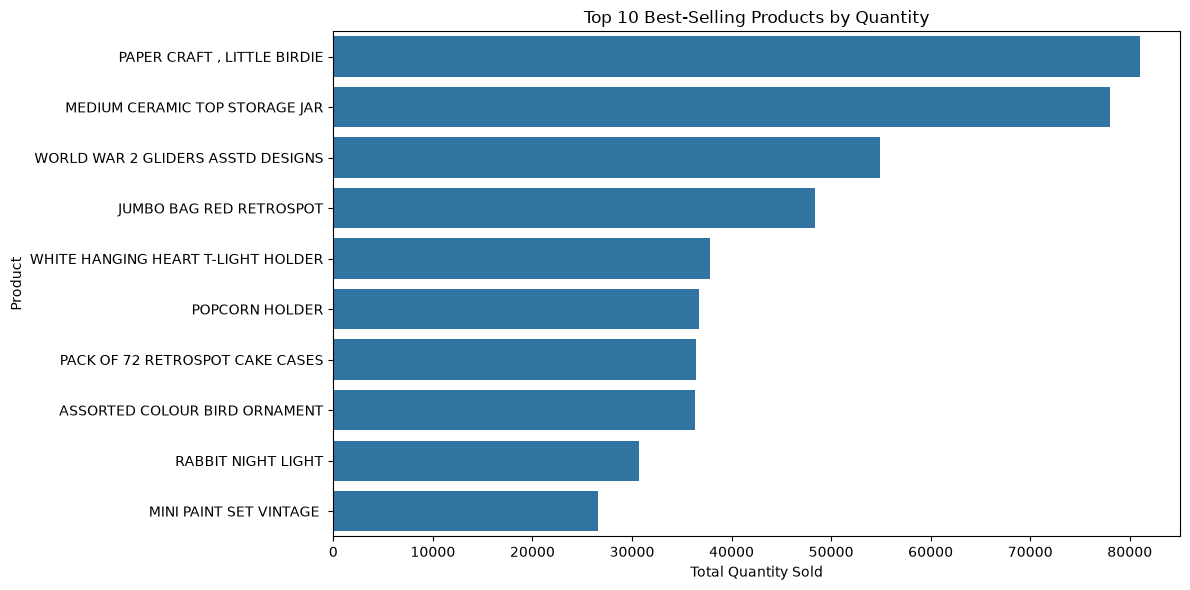

In [16]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_products,
    x="Total_Quantity",
    y="Description"
)

plt.title("Top 10 Best-Selling Products by Quantity")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [17]:
# Extract year and month from InvoiceDate
sales_df["YearMonth"] = sales_df["InvoiceDate"].dt.to_period("M")

# Calculate monthly revenue
monthly_sales = (
    sales_df.groupby("YearMonth")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Orders=("InvoiceNo", "nunique")
    )
    .reset_index()
)

# Convert YearMonth to string for display
monthly_sales["YearMonth"] = monthly_sales["YearMonth"].astype(str)

# Display monthly sales
monthly_sales

,YearMonth,Total_Revenue,Total_Orders
0,2010-12,821452.730,1559
1,2011-01,689811.610,1086
2,2011-02,522545.560,1100
3,2011-03,716215.260,1454
4,2011-04,536968.491,1246
5,2011-05,769296.610,1681
6,2011-06,760547.010,1533
7,2011-07,718076.121,1475
8,2011-08,757841.380,1361
9,2011-09,1056435.192,1837


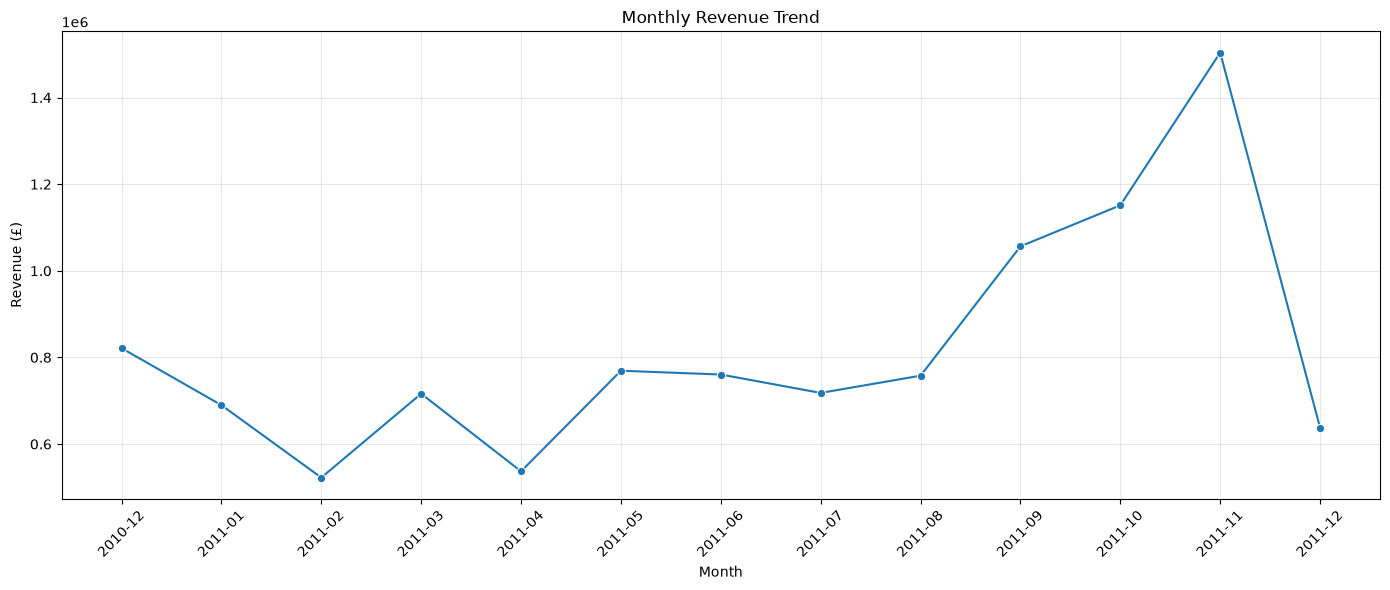

In [18]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_sales,
    x="YearMonth",
    y="Total_Revenue",
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
best_month = monthly_sales.loc[
    monthly_sales["Total_Revenue"].idxmax()
]

print("Highest Revenue Month:", best_month["YearMonth"])
print(f"Revenue: £{best_month['Total_Revenue']:,.2f}")

Highest Revenue Month: 2011-11
Revenue: £1,503,866.78


In [20]:
# Calculate revenue and orders by country
country_sales = (
    sales_df.groupby("Country")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Orders=("InvoiceNo", "nunique"),
        Total_Quantity=("Quantity", "sum")
    )
    .sort_values(
        by="Total_Revenue",
        ascending=False
    )
    .reset_index()
)

# Display the top 10 countries
country_sales.head(10)

,Country,Total_Revenue,Total_Orders,Total_Quantity
0,United Kingdom,9001744.094,18019,4646906
1,Netherlands,285446.340,94,200361
2,EIRE,283140.520,288,147007
3,Germany,228678.400,457,119154
4,France,209625.370,392,112060
5,Australia,138453.810,57,83891
6,Spain,61558.560,90,27933
7,Switzerland,57067.600,54,30617
8,Belgium,41196.340,98,23237
9,Sweden,38367.830,36,36078


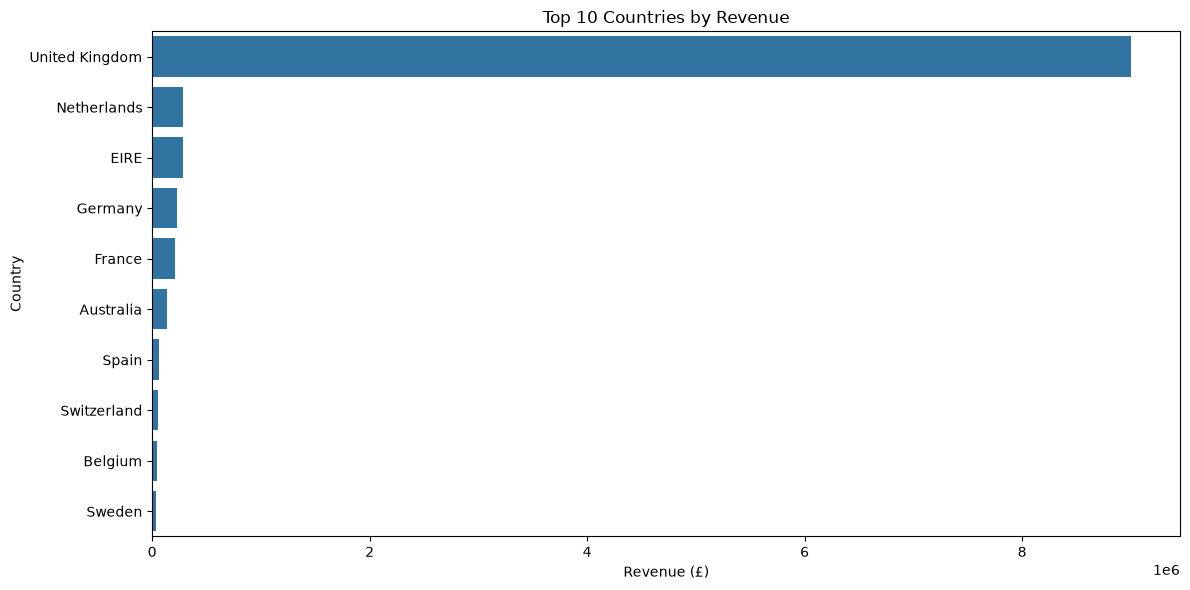

In [21]:
# Top 10 countries by revenue
top_countries = country_sales.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_countries,
    x="Total_Revenue",
    y="Country"
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [22]:
uk_revenue = sales_df.loc[
    sales_df["Country"] == "United Kingdom",
    "Revenue"
].sum()

total_revenue = sales_df["Revenue"].sum()

uk_share = (uk_revenue / total_revenue) * 100

print(f"UK Revenue: £{uk_revenue:,.2f}")
print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"UK Share of Revenue: {uk_share:.2f}%")

UK Revenue: £9,001,744.09
Total Revenue: £10,642,110.80
UK Share of Revenue: 84.59%


In [23]:
# Analyze sales by customer
customer_sales = (
    sales_df.dropna(subset=["CustomerID"])
    .groupby("CustomerID")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Orders=("InvoiceNo", "nunique"),
        Total_Quantity=("Quantity", "sum")
    )
    .sort_values(
        by="Total_Revenue",
        ascending=False
    )
    .reset_index()
)

# Display the top 10 customers
customer_sales.head(10)

,CustomerID,Total_Revenue,Total_Orders,Total_Quantity
0,14646,280206.02,73,196915
1,18102,259657.30,60,64124
2,17450,194390.79,46,69973
3,16446,168472.50,2,80997
4,14911,143711.17,201,80240
5,12415,124914.53,21,77374
6,14156,117210.08,55,57768
7,17511,91062.38,31,64549
8,16029,80850.84,63,40108
9,12346,77183.60,1,74215


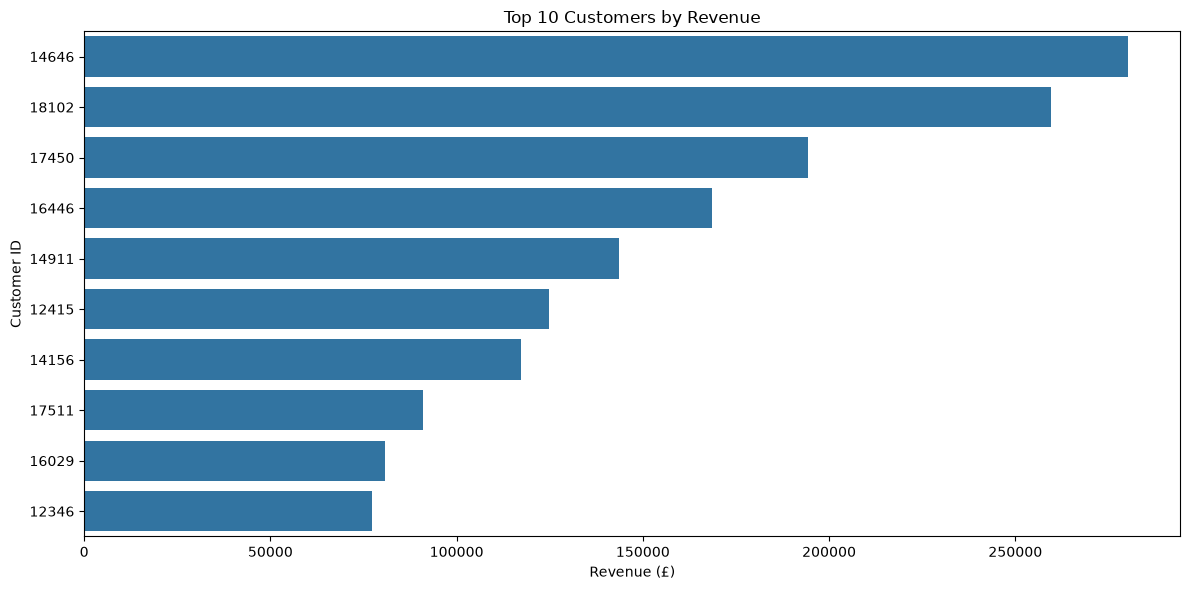

In [24]:
top_customers = customer_sales.head(10).copy()

top_customers["CustomerID"] = (
    top_customers["CustomerID"].astype(str)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_customers,
    x="Total_Revenue",
    y="CustomerID"
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()

In [25]:
total_revenue = sales_df["Revenue"].sum()
total_orders = sales_df["InvoiceNo"].nunique()

average_order_value = total_revenue / total_orders

print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Average Order Value: £{average_order_value:,.2f}")

Total Revenue: £10,642,110.80
Total Orders: 19,960
Average Order Value: £533.17


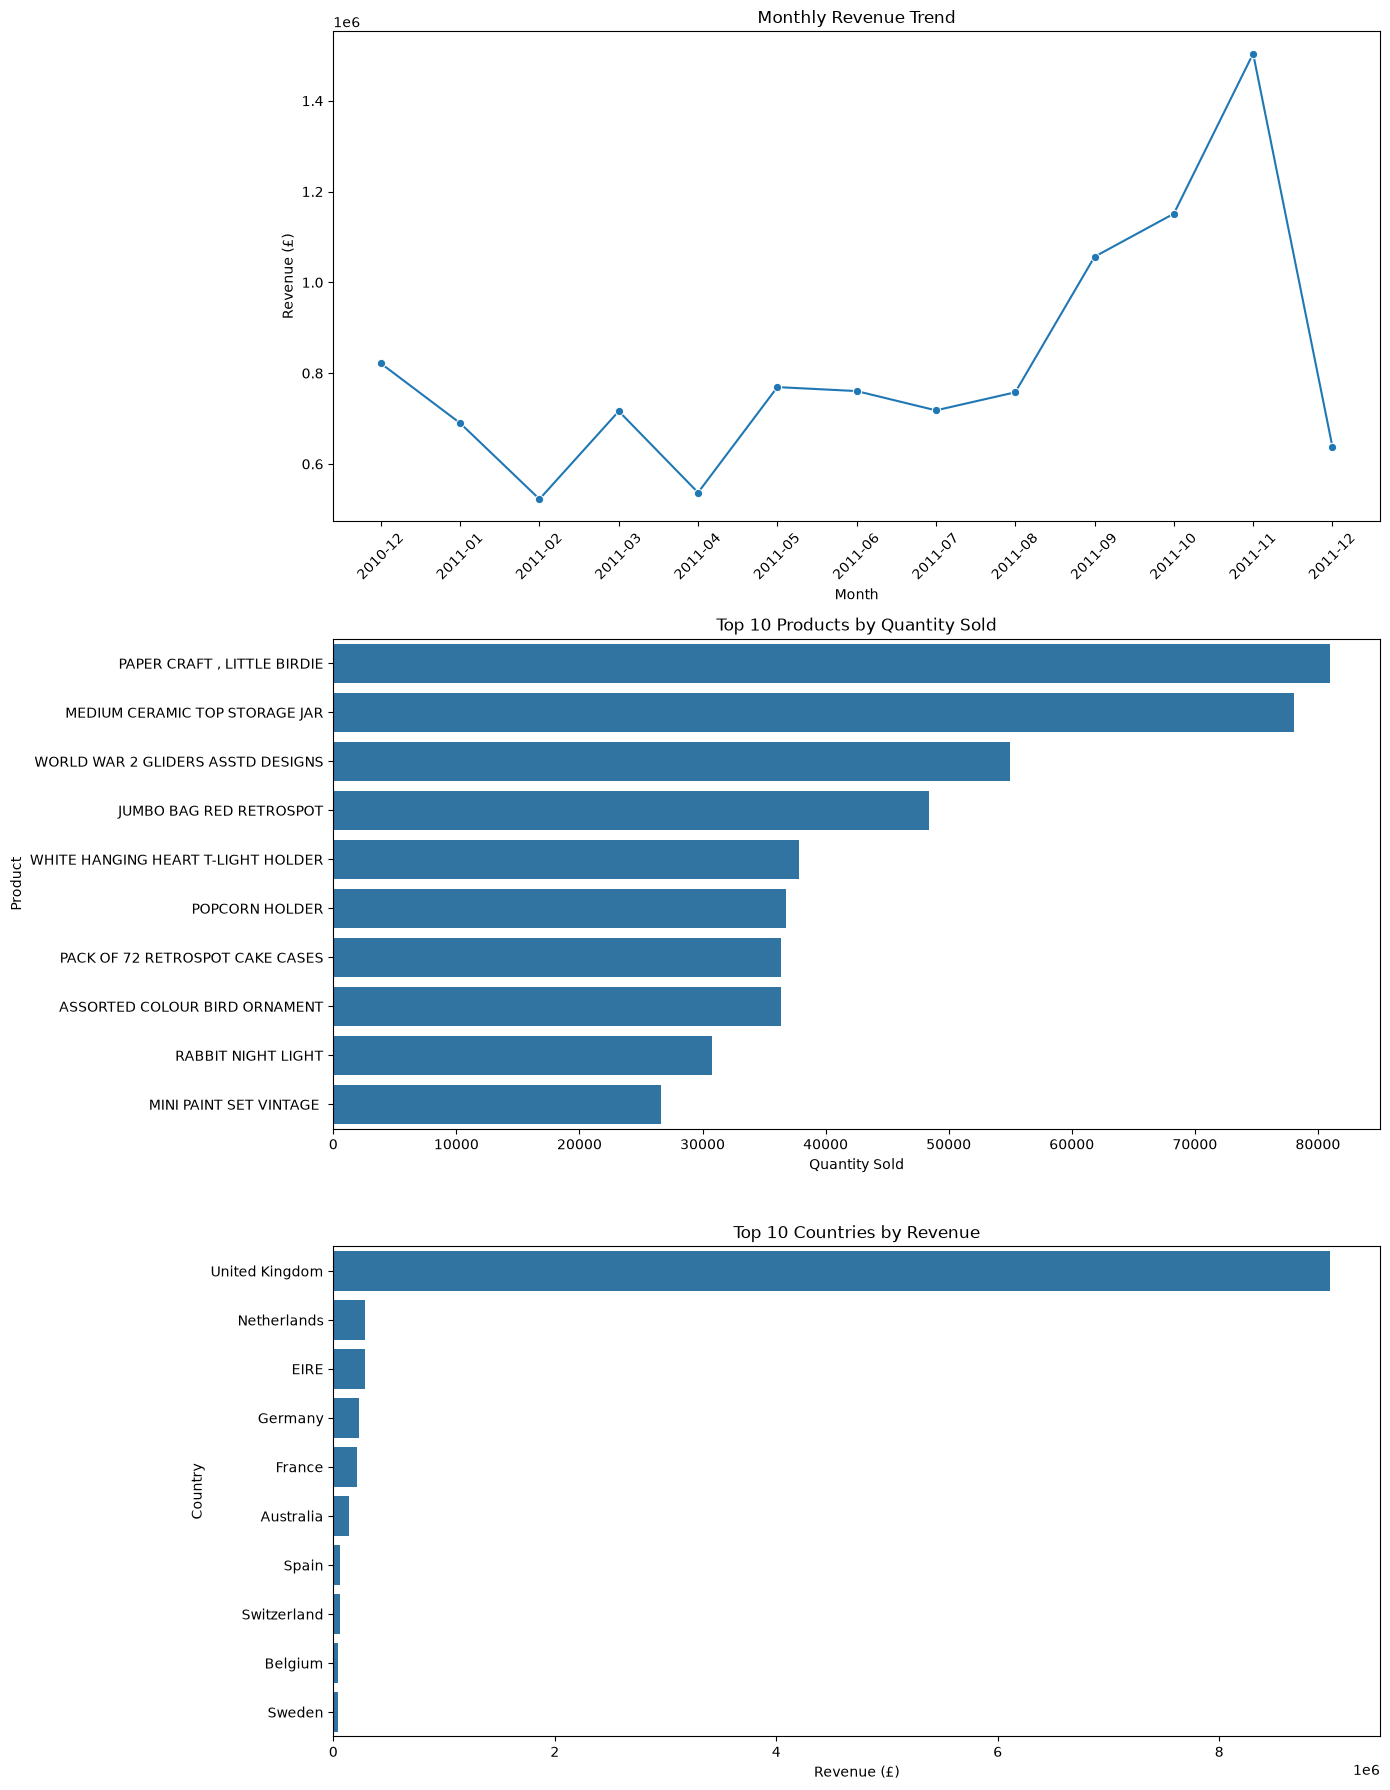

In [27]:
fig, axes = plt.subplots(3, 1, figsize=(14, 18))

# 1. Monthly revenue
sns.lineplot(
    data=monthly_sales,
    x="YearMonth",
    y="Total_Revenue",
    marker="o",
    ax=axes[0]
)
axes[0].set_title("Monthly Revenue Trend")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Revenue (£)")
axes[0].tick_params(axis="x", rotation=45)

# 2. Top products by quantity
sns.barplot(
    data=top_products,
    x="Total_Quantity",
    y="Description",
    ax=axes[1]
)
axes[1].set_title("Top 10 Products by Quantity Sold")
axes[1].set_xlabel("Quantity Sold")
axes[1].set_ylabel("Product")

# 3. Top countries by revenue
sns.barplot(
    data=top_countries,
    x="Total_Revenue",
    y="Country",
    ax=axes[2]
)
axes[2].set_title("Top 10 Countries by Revenue")
axes[2].set_xlabel("Revenue (£)")
axes[2].set_ylabel("Country")

plt.tight_layout()
plt.show()

In [28]:
from pathlib import Path

output_folder = Path("project_outputs")
output_folder.mkdir(exist_ok=True)

# Save cleaned sales data
sales_df.to_csv(
    output_folder / "cleaned_sales_data.csv",
    index=False
)

# Save KPI summary
kpi_summary.to_csv(
    output_folder / "sales_kpi_summary.csv",
    index=False
)

# Save the combined visualization
fig.savefig(
    output_folder / "sales_analysis_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

print("Project outputs saved successfully!")

Project outputs saved successfully!
